In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("solar_system.csv", index_col=0)
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Shape: (20, 10)
Rows: 20
Columns: 10


In [3]:
df.head()

,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
Attribute,,,,,,,,,,
Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3


In [4]:
df.tail()

,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
Attribute,,,,,,,,,,
Mean Temperature (C),167,464,15,-20,-65,-110,-140,-195,-200,-225
Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
Number of Moons,0,0,1,0,2,95,274,28,16,5
Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown


In [5]:
print(list(df.columns))

['Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune', 'Pluto']


In [6]:
print(list(df.index))

['Mass (10^24kg)', 'Diameter (km)', 'Density (kg/m^3)', 'Gravity (m/s^2)', 'Escape Velocity (km/s)', 'Rotation Period (hours)', 'Length of Day (hours)', 'Distance from Sun (10^6 km)', 'Perihelion (10^6 km)', 'Aphelion (10^6 km)', 'Orbital Period (days)', 'Orbital Velocity (km/s)', 'Orbital Inclination (deg)', 'Orbital Eccentricity', 'Obliquity to Orbit (deg)', 'Mean Temperature (C)', 'Surface Pressure (bars)', 'Number of Moons', 'Ring System?', 'Global Magnetic Field?']


In [8]:
perihelion = df.iloc[8].astype(float)
aphelion = df.iloc[9].astype(float)
orbital_period = df.iloc[10].astype(float)

In [9]:
'''
Perihelion: the point in an orbit where a celestial body is closest to the sun
Aphelion: the point where a celestial body is farthest from the sun
Semi-major axis: half of the longest diamter of an elliptical orbit; equivalent to the aveage of the perihelion and aphelion distances
'''

'\nPerihelion: the point in an orbit where a celestial body is closest to the sun\nAphelion: the point where a celestial body is farthest from the sun\nSemi-major axis: half of the longest diamter of an elliptical orbit; equivalent to the aveage of the perihelion and aphelion distances\n'

In [11]:
semi_major_axis = (perihelion+aphelion)/2
semi_major_axis.name = "Semi-major Axis (10^6 km)"
df=pd.concat([df, semi_major_axis.to_frame().T])
df.tail()

,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
Number of Moons,0,0,1,0,2,95,274,28,16,5
Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown
Semi-major Axis (10^6 km),57.9,108.2,149.6,0.3845,228.0,778.5,1432.05,2867.05,4515.0,5906.35


In [12]:
print("Shape:", df.shape)

Shape: (21, 10)


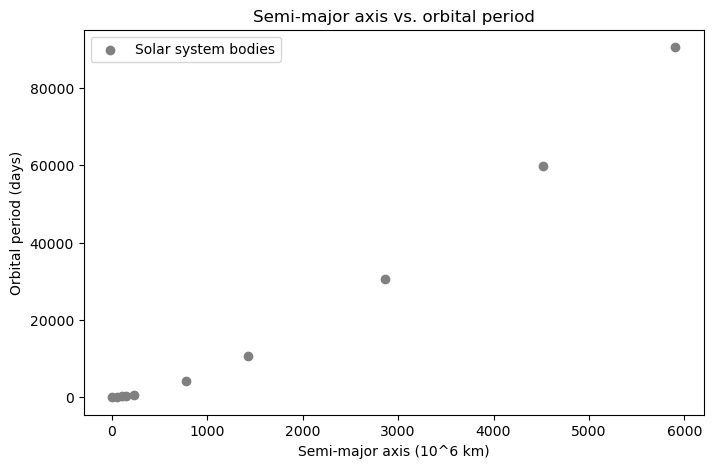

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(semi_major_axis, orbital_period, color="gray", label="Solar system bodies")
plt.xlabel("Semi-major axis (10^6 km)")
plt.ylabel("Orbital period (days)")
plt.title("Semi-major axis vs. orbital period")
plt.legend()
plt.show()

In [15]:
def keplers_third_law(a, m):
    return m * a ** 1.5
mask = semi_major_axis.index != "Moon"
a = semi_major_axis[mask]
T = orbital_period[mask]
popt, pcov = curve_fit(keplers_third_law, a, T)
m_fit = popt[0]
print(f"Fit: T={m_fit:.2f} *a^1.5")

Fit: T=0.20 *a^1.5


In [16]:
residuals = T - keplers_third_law(a, m_fit)
chi2 = np.sum(residuals**2)
dof = len(a) - len(popt)
chi2_reduced = chi2 / dof
print(f"Reduced chi-squared: {chi2_reduced:.2f}")

Reduced chi-squared: 46343.46


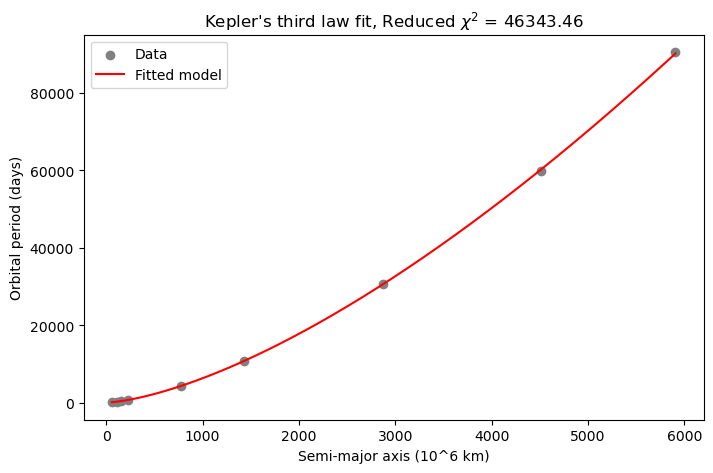

In [17]:
a_smooth = np.linspace(a.min(), a.max(), 500)
plt.figure(figsize=(8, 5))
plt.scatter(a, T, color="gray", label="Data")
plt.plot(a_smooth, keplers_third_law(a_smooth, m_fit), color="red", label="Fitted model")
plt.xlabel("Semi-major axis (10^6 km)")
plt.ylabel("Orbital period (days)")
plt.title(f"Kepler's third law fit, Reduced $\\chi^2$ = {chi2_reduced:.2f}")
plt.legend()
plt.show()

In [18]:
df.to_csv("kepler.csv")